In [ ]:
import pandas as pd
import numpy as np
import time

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import mutual_info_classif

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
train_data = pd.read_csv("train_dataset.csv")
test_data = pd.read_csv("test_dataset.csv")

print("Train Shape:", train_data.shape)
print("Test Shape:", test_data.shape)

Train Shape: (1255480, 40)
Test Shape: (313870, 40)


In [3]:
print("Train Dataset Shape:", train_data.shape)
print("Test Dataset Shape:", test_data.shape)

print("\nTrain Columns:")
print(train_data.columns.tolist())

Train Dataset Shape: (1255480, 40)
Test Dataset Shape: (313870, 40)

Train Columns:
['Header_Length', 'Protocol Type', 'Time_To_Live', 'Rate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Variance', 'Label']


In [4]:
print("Training Dataset Class Distribution:")
print(train_data["Label"].value_counts())

print("\nTesting Dataset Class Distribution:")
print(test_data["Label"].value_counts())

Training Dataset Class Distribution:
Label
Benign       875101
DDoS-UDP     182701
DDoS-TCP     174646
DDoS-HTTP     23032
Name: count, dtype: int64

Testing Dataset Class Distribution:
Label
Benign       218775
DDoS-UDP      45676
DDoS-TCP      43661
DDoS-HTTP      5758
Name: count, dtype: int64


In [5]:
# Clean Training Dataset
train_data.replace([np.inf, -np.inf], np.nan, inplace=True)
train_data.fillna(0, inplace=True)

# Clean Testing Dataset
test_data.replace([np.inf, -np.inf], np.nan, inplace=True)
test_data.fillna(0, inplace=True)

print("Train Missing Values:", train_data.isnull().sum().sum())
print("Test Missing Values:", test_data.isnull().sum().sum())

Train Missing Values: 0
Test Missing Values: 0


In [6]:
# Encode labels

encoder = LabelEncoder()

train_data["Label"] = encoder.fit_transform(train_data["Label"])
test_data["Label"] = encoder.transform(test_data["Label"])

print("Class Mapping")

for i, cls in enumerate(encoder.classes_):
    print(f"{i} = {cls}")

Class Mapping
0 = Benign
1 = DDoS-HTTP
2 = DDoS-TCP
3 = DDoS-UDP


In [7]:
# Take a sample from training data for faster Information Gain calculation

sample_data = train_data.sample(
    n=min(100000, len(train_data)),
    random_state=42
)

X_sample = sample_data.drop("Label", axis=1)

y_sample = sample_data["Label"]

print("Calculating Information Gain...")

Calculating Information Gain...


In [8]:
scores = mutual_info_classif(
    X_sample,
    y_sample,
    random_state=42
)

feature_scores = pd.DataFrame({
    "Feature": X_sample.columns,
    "Information_Gain": scores
})

feature_scores = feature_scores.sort_values(
    by="Information_Gain",
    ascending=False
)

feature_scores

,Feature,Information_Gain
0,Header_Length,0.793740
8,ack_flag_number,0.640093
37,Number,0.616543
22,TCP,0.599186
35,Tot size,0.586946
30,Tot sum,0.586321
33,AVG,0.586006
11,ack_count,0.584121
23,UDP,0.564473
16,HTTPS,0.512200


In [9]:
ranked_features = feature_scores["Feature"].tolist()

In [10]:
feature_counts = [3, 5, 10, 15, 20, 25, 35, 39]

In [ ]:

results = []

for k in feature_counts:

    print(f"Testing Top-{k} Features")

    selected_features = ranked_features[:k]

    # Training data
    X_train = train_data[selected_features]
    y_train = train_data["Label"]

    # Testing data
    X_test = test_data[selected_features]
    y_test = test_data["Label"]

    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred) * 100

    results.append([k, accuracy])

Testing Top-3 Features
Testing Top-5 Features
Testing Top-10 Features
Testing Top-15 Features
Testing Top-20 Features
Testing Top-25 Features
Testing Top-35 Features
Testing Top-39 Features


In [ ]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Number_of_Features",
        "Accuracy"
    ]
)

results_df

,Number_of_Features,Accuracy
0,3,99.895180
1,5,99.924172
2,10,99.938510
3,15,99.967502
4,20,99.968777
5,25,99.975149
6,35,99.978335
7,39,99.975786


In [13]:
print(feature_scores.head(15))

            Feature  Information_Gain
0     Header_Length          0.793740
8   ack_flag_number          0.640093
37           Number          0.616543
22              TCP          0.599186
35         Tot size          0.586946
30          Tot sum          0.586321
33              AVG          0.586006
11        ack_count          0.584121
23              UDP          0.564473
16            HTTPS          0.512200
36              IAT          0.498904
3              Rate          0.488401
2      Time_To_Live          0.473543
38         Variance          0.459007
34              Std          0.458875


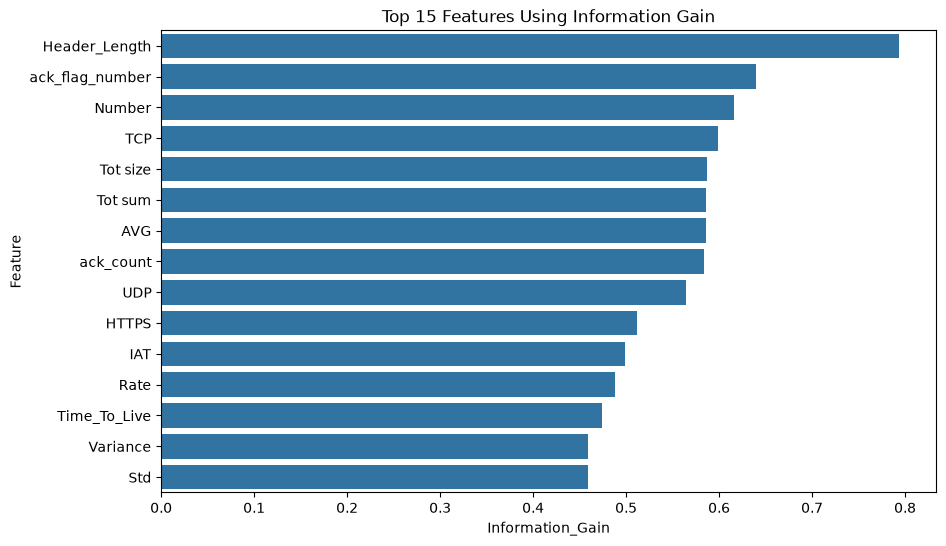

In [14]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_scores.head(15),
    x="Information_Gain",
    y="Feature"
)

plt.title("Top 15 Features Using Information Gain")

plt.show()

In [15]:
top_k = 10

selected_features = feature_scores.head(top_k)["Feature"].tolist()


print("Selected Features")

for feature in selected_features:
    print(feature)

Selected Features
Header_Length
ack_flag_number
Number
TCP
Tot size
Tot sum
AVG
ack_count
UDP
HTTPS


In [16]:
selected_features = ranked_features[:10]   # Top 10 features

X_train = train_data[selected_features]
y_train = train_data["Label"]

X_test = test_data[selected_features]
y_test = test_data["Label"]



In [17]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

print("Training completed")

Training completed


In [18]:
# Train model
start_train = time.time()

rf.fit(X_train, y_train)

training_time = time.time() - start_train

print("Training Time:", round(training_time, 2), "seconds")

Training Time: 16.38 seconds


In [19]:
start_predict = time.time()

y_pred = rf.predict(X_test)

prediction_time = time.time() - start_predict

print("Prediction Time:", round(prediction_time, 4), "seconds")

Prediction Time: 0.2415 seconds


In [20]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    average='weighted'
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted'
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted'
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.9993850957402747
Precision: 0.9993850043119937
Recall   : 0.9993850957402747
F1 Score : 0.999385036232379


In [21]:
# Classification Report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=encoder.classes_
    )
)

              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00    218775
   DDoS-HTTP       0.99      0.99      0.99      5758
    DDoS-TCP       1.00      1.00      1.00     43661
    DDoS-UDP       1.00      1.00      1.00     45676

    accuracy                           1.00    313870
   macro avg       1.00      1.00      1.00    313870
weighted avg       1.00      1.00      1.00    313870



In [22]:
# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred
)
cm

array([[218775,      0,      0,      0],
       [     2,   5697,     36,     23],
       [     0,     29,  43601,     31],
       [     2,     28,     42,  45604]])

In [23]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
2,Number,0.227064
1,ack_flag_number,0.152923
8,UDP,0.114957
0,Header_Length,0.106335
6,AVG,0.102176
3,TCP,0.086117
4,Tot size,0.084053
7,ack_count,0.068088
9,HTTPS,0.052977
5,Tot sum,0.005309


In [24]:
#Final result table
results = pd.DataFrame({
    "Model": ["Random Forest"],
    "Accuracy": [accuracy*100],
    "Precision": [precision*100],
    "Recall": [recall*100],
    "F1 Score": [f1*100],
    "Training Time (s)": [training_time],
    "Prediction Time (s)": [prediction_time]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (s),Prediction Time (s)
0,Random Forest,99.93851,99.9385,99.93851,99.938504,16.382399,0.241464


In [25]:
results.to_csv(
    "RandomForest_Results.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.
